# Failure Pattern Statistical Analysis — AI4I Predictive Maintenance Analytics

I examine how sensor readings differ between failed and non-failed observations, quantify the size and uncertainty of those differences, and describe failure patterns by product type and failure flag.

I extend the sensor comparisons from the hypothesis-testing stage using the **same development observations** and **same corrected p-values**. Repeating the two-group comparison with Welch's t-test is an equivalent calculation, not independent confirmation.

**Inputs**
- `data/cleaned/ai4i2020_cleaned.csv`
- The split manifest and settings in `reports/smote/`
- The analysis settings, observation manifest, and H2 sensor results in `reports/hypothesis_testing/`

**Outputs:** tables and settings in `reports/failure_statistics/`, and charts in `visuals/failure_statistics/`.

I use observed development rows without oversampling or class weighting. Final-test rows remain excluded.


## 1. Set up the analysis

I use Welch's t-test for mean differences, a sample-size-weighted pooled standard deviation for Cohen's d, and its small-sample correction for Hedges' g. I estimate pointwise Hedges' g intervals by resampling observations separately within the two outcome groups.

References: [Welch's t-test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html), [bias-corrected standardized mean differences](https://www.statsmodels.org/stable/generated/statsmodels.stats.meta_analysis.effectsize_smd.html), [Wilson proportion intervals](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportion_confint.html).


In [1]:
from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
import scipy
import statsmodels
from statsmodels.stats.proportion import proportion_confint

ALPHA = 0.05
SEED = 42
BOOTSTRAP_REPEATS = 1000
BOOTSTRAP_BATCH_SIZE = 50

SENSOR_COLUMNS = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
FAILURE_FLAGS = ["TWF", "HDF", "PWF", "OSF", "RNF"]
COLORS = {0: "#0072B2", 1: "#D55E00"}
plt.rcParams["figure.figsize"] = (9, 5)

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

print(f"Python: {platform.python_version()}")
print(f"SciPy: {scipy.__version__}; statsmodels: {statsmodels.__version__}")


Python: 3.13.5
SciPy: 1.15.3; statsmodels: 0.14.4


Matplotlib is building the font cache; this may take a moment.


## 2. Validate inputs and reuse the analysis sample

I verify the cleaned-data checksum, split assignments, target labels, and the exact observation set used in the hypothesis notebook. If an input has changed, I stop rather than silently combine incompatible results.


In [2]:
current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in (current, *current.parents)
     if (folder / "data" / "cleaned" / "ai4i2020_cleaned.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find the cleaned CSV. Run the cleaning notebook first.")

input_paths = {
    "data": PROJECT_ROOT / "data" / "cleaned" / "ai4i2020_cleaned.csv",
    "split_manifest": PROJECT_ROOT / "reports" / "smote" / "split_manifest.csv",
    "smote_settings": PROJECT_ROOT / "reports" / "smote" / "experiment_settings.json",
    "hypothesis_settings": PROJECT_ROOT / "reports" / "hypothesis_testing" / "analysis_settings.json",
    "hypothesis_observations": PROJECT_ROOT / "reports" / "hypothesis_testing" / "analysis_observations.csv",
    "hypothesis_H2_results": PROJECT_ROOT / "reports" / "hypothesis_testing" / "h2_sensor_mean_tests.csv",
}
for name, path in input_paths.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {path.relative_to(PROJECT_ROOT)}. Run the preceding notebooks first."
        )
input_checksums = {name: sha256(path) for name, path in input_paths.items()}
smote_settings = json.loads(input_paths["smote_settings"].read_text(encoding="utf-8"))
hypothesis_settings = json.loads(input_paths["hypothesis_settings"].read_text(encoding="utf-8"))

if input_checksums["data"] != smote_settings["input_sha256"]:
    raise ValueError("The cleaned dataset differs from the SMOTE experiment input.")
if input_checksums["data"] != hypothesis_settings["input_sha256"]:
    raise ValueError("The cleaned dataset differs from the hypothesis analysis input.")
if input_checksums["split_manifest"] != hypothesis_settings["split_manifest_sha256"]:
    raise ValueError("The split manifest differs from the hypothesis analysis manifest.")
if hypothesis_settings["included_splits"] != ["train", "validation"]:
    raise ValueError("Expected train and validation development observations.")
if hypothesis_settings["multiple_test_method"] != "holm" or hypothesis_settings["primary_test_count"] != 6:
    raise ValueError("Expected the six-test Holm correction from the hypothesis notebook.")
if not np.isclose(hypothesis_settings["alpha"], ALPHA):
    raise ValueError("The hypothesis report uses a different alpha.")

df = pd.read_csv(input_paths["data"])
manifest = pd.read_csv(input_paths["split_manifest"])
prior_observations = pd.read_csv(input_paths["hypothesis_observations"])
prior_h2 = pd.read_csv(input_paths["hypothesis_H2_results"], index_col="sensor")

required_columns = ["UDI", "Type", "Machine failure", *SENSOR_COLUMNS, *FAILURE_FLAGS]
missing = sorted(set(required_columns) - set(df.columns))
if missing:
    raise ValueError(f"Missing columns: {missing}")
if df[required_columns].isna().any().any() or manifest.isna().any().any():
    raise ValueError("Required input values must be complete.")
if df["UDI"].duplicated().any() or manifest["UDI"].duplicated().any():
    raise ValueError("UDI values must be unique.")
if set(df["UDI"]) != set(manifest["UDI"]):
    raise ValueError("The manifest must cover exactly the cleaned dataset.")
if not set(manifest["split"]).issubset({"train", "validation", "final_test"}):
    raise ValueError("Unexpected split assignments.")

joined = df.merge(
    manifest.rename(columns={"Machine failure": "manifest_target"}),
    on="UDI", validate="one_to_one",
)
if not joined["Machine failure"].eq(joined["manifest_target"]).all():
    raise ValueError("Targets differ between the dataset and split manifest.")

analysis = joined.loc[joined["split"].isin(["train", "validation"])].copy()
test_udi = set(joined.loc[joined["split"].eq("final_test"), "UDI"])
if not set(analysis["UDI"]).isdisjoint(test_udi):
    raise ValueError("Final-test observations entered the analysis sample.")
if set(analysis["UDI"]) != set(prior_observations["UDI"]) or prior_observations["UDI"].duplicated().any():
    raise ValueError("The analysis sample differs from the hypothesis-testing sample.")
for column in ["Machine failure", *FAILURE_FLAGS]:
    if not analysis[column].isin([0, 1]).all():
        raise ValueError(f"{column} must be binary.")
if analysis["Machine failure"].nunique() != 2:
    raise ValueError("Both machine-failure classes are required.")
if not analysis["Type"].isin(["L", "M", "H"]).all():
    raise ValueError("Expected product Type values L, M, or H.")
if not np.isfinite(analysis[SENSOR_COLUMNS].to_numpy(dtype=float)).all():
    raise ValueError("Sensor readings must be numeric and finite.")
if set(prior_h2.index) != set(SENSOR_COLUMNS):
    raise ValueError("The prior H2 report does not match the five sensor comparisons.")

REPORTS_DIR = PROJECT_ROOT / "reports" / "failure_statistics"
VISUALS_DIR = PROJECT_ROOT / "visuals" / "failure_statistics"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

failed = analysis.loc[analysis["Machine failure"].eq(1)]
not_failed = analysis.loc[analysis["Machine failure"].eq(0)]
if min(len(failed), len(not_failed)) < 2:
    raise ValueError("At least two observations are required in each outcome group.")

print(f"Development observations: {len(analysis):,}")
print(f"No failure: {len(not_failed):,}; failure: {len(failed):,}")
print(f"Final-test observations excluded: {len(test_udi):,}")
display(analysis.groupby("Machine failure")[SENSOR_COLUMNS].agg(["mean", "median", "std"]).round(3))


Development observations: 8,000
No failure: 7,729; failure: 271
Final-test observations excluded: 2,000


Air temperature [K]         ... Tool wear [min]        
                               mean median  ...          median     std
Machine failure                             ...                        
0                           299.973  300.0  ...           106.0  62.860
1                           300.923  301.6  ...           166.0  74.854

[2 rows x 15 columns]

## 3. Compare sensor distributions

I use common histogram bins for each sensor and normalize each outcome group separately. The vertical scale is density, so the much larger no-failure group does not dominate solely because it has more observations.

The dashed lines mark group medians. All observed values are included in these histograms.


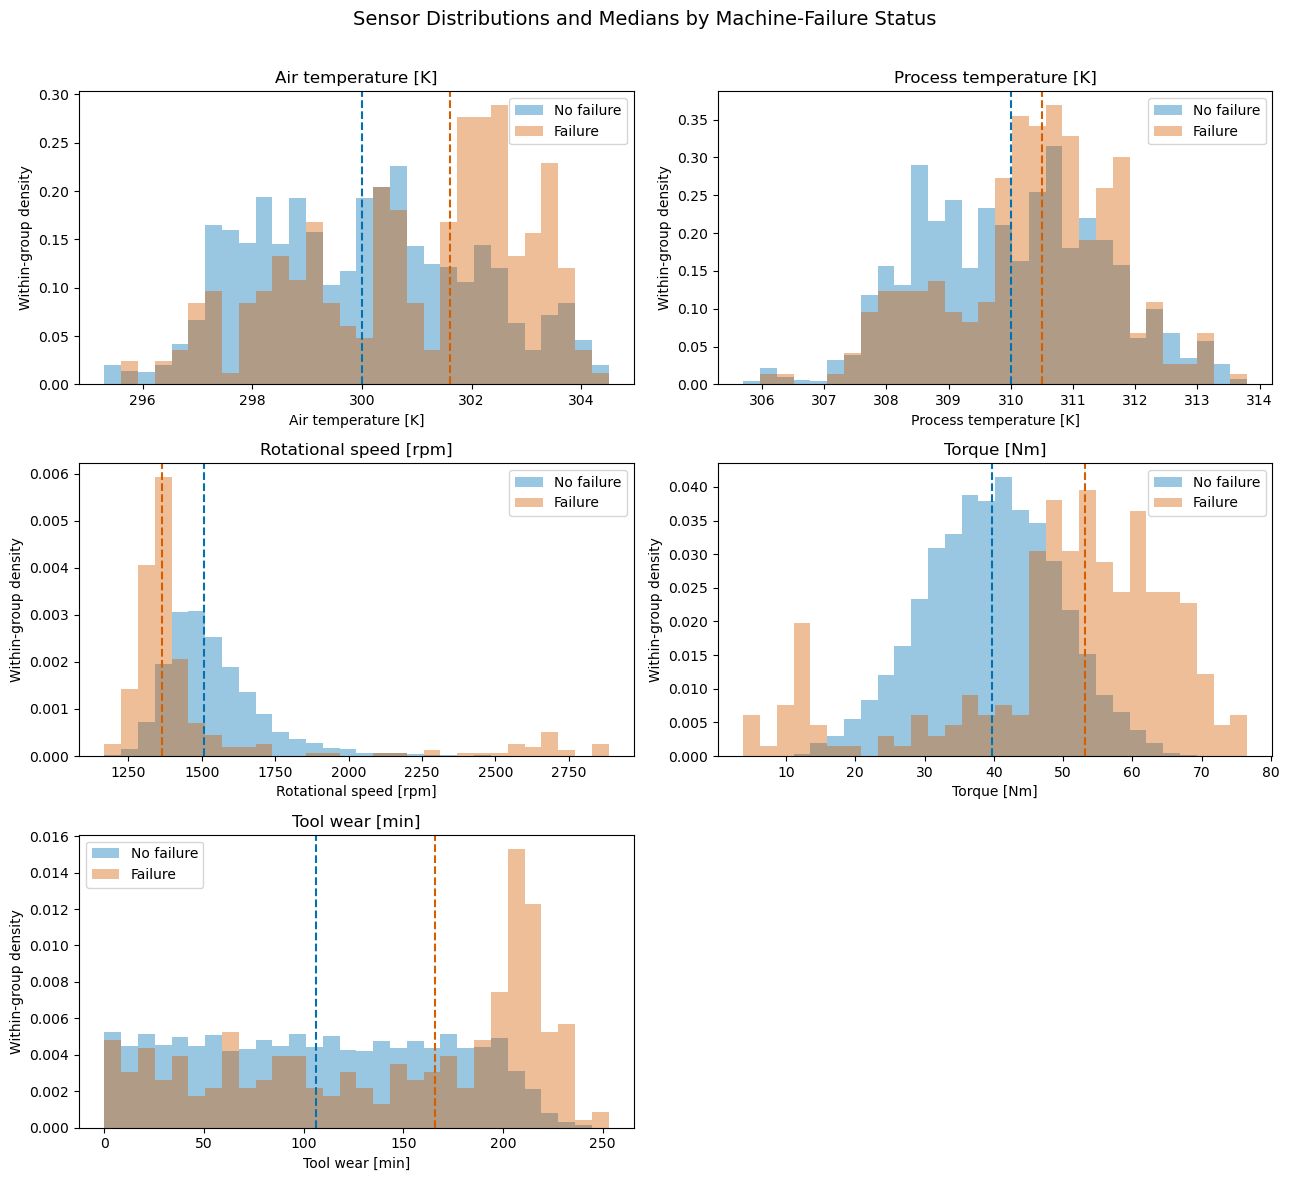

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for ax, sensor in zip(axes.ravel(), SENSOR_COLUMNS):
    bins = np.histogram_bin_edges(analysis[sensor], bins=30)
    for label, group, name in [
        (0, not_failed, "No failure"),
        (1, failed, "Failure"),
    ]:
        values = group[sensor].to_numpy()
        ax.hist(
            values, bins=bins, density=True,
            alpha=0.40, color=COLORS[label], label=name,
        )
        ax.axvline(np.median(values), color=COLORS[label], linestyle="--", linewidth=1.5)
    ax.set_title(sensor)
    ax.set_xlabel(sensor)
    ax.set_ylabel("Within-group density")
    ax.legend()
axes.ravel()[-1].set_visible(False)
fig.suptitle("Sensor Distributions and Medians by Machine-Failure Status", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(VISUALS_DIR / "sensor_distributions.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 4. Quantify mean differences and standardized effects

I define every difference as **failure minus no failure**.

- The Welch confidence interval reports the difference in the sensor's physical units.
- Cohen's d divides the mean difference by the sample-size-weighted pooled standard deviation.
- Hedges' g applies a small-sample correction to d. Positive values indicate higher average readings in the failure group.

The pooled scale is a descriptive standardization; it does not assume the group variances are equal for the Welch test. A standardized mean difference is not a causal effect or a predictive feature-importance score.

I calculate 95% percentile bootstrap intervals for g by resampling separately within each group. These are pointwise intervals, not simultaneous intervals across all sensors, and assume observations are sufficiently independent within each group. Bootstrap draws are used only to estimate uncertainty, not to balance classes or train models.


In [4]:
def standardized_effect(group1, group0):
    n1, n0 = len(group1), len(group0)
    pooled_variance = (
        (n1 - 1) * np.var(group1, ddof=1)
        + (n0 - 1) * np.var(group0, ddof=1)
    ) / (n1 + n0 - 2)
    if pooled_variance <= 0:
        raise ValueError("A positive pooled variance is required.")
    cohen_d = (np.mean(group1) - np.mean(group0)) / np.sqrt(pooled_variance)
    correction = 1 - 3 / (4 * (n1 + n0) - 9)
    return float(cohen_d), float(correction * cohen_d)

def bootstrap_hedges_g(group1, group0, seed):
    rng = np.random.default_rng(seed)
    n1, n0 = len(group1), len(group0)
    correction = 1 - 3 / (4 * (n1 + n0) - 9)
    draws = []
    for start in range(0, BOOTSTRAP_REPEATS, BOOTSTRAP_BATCH_SIZE):
        batch = min(BOOTSTRAP_BATCH_SIZE, BOOTSTRAP_REPEATS - start)
        sampled1 = group1[rng.integers(0, n1, size=(batch, n1))]
        sampled0 = group0[rng.integers(0, n0, size=(batch, n0))]
        pooled_variance = (
            (n1 - 1) * sampled1.var(axis=1, ddof=1)
            + (n0 - 1) * sampled0.var(axis=1, ddof=1)
        ) / (n1 + n0 - 2)
        draws.append(
            correction * (sampled1.mean(axis=1) - sampled0.mean(axis=1))
            / np.sqrt(pooled_variance)
        )
    values = np.concatenate(draws)
    if not np.isfinite(values).all():
        raise ValueError("Nonfinite effect-size bootstrap estimates.")
    return np.quantile(values, [ALPHA / 2, 1 - ALPHA / 2])

sensor_rows = []
for index, sensor in enumerate(SENSOR_COLUMNS):
    group1 = failed[sensor].to_numpy(dtype=float)
    group0 = not_failed[sensor].to_numpy(dtype=float)
    welch = stats.ttest_ind(
        group1, group0, equal_var=False, alternative="two-sided", nan_policy="raise",
    )
    interval = welch.confidence_interval(confidence_level=1 - ALPHA)
    cohen_d, hedges_g = standardized_effect(group1, group0)
    g_low, g_high = bootstrap_hedges_g(group1, group0, SEED + index)

    # Two-group Welch ANOVA and Welch's t-test should agree on the p-value.
    if not np.isclose(welch.pvalue, prior_h2.loc[sensor, "raw_p_value"], rtol=1e-8, atol=1e-25):
        raise ValueError(f"Welch results differ from the hypothesis notebook for {sensor}.")
    if not np.isclose(
        group1.mean() - group0.mean(),
        prior_h2.loc[sensor, "mean_difference_failure_minus_no_failure"],
    ):
        raise ValueError(f"Mean differences disagree with the prior analysis for {sensor}.")

    adjusted_p = float(prior_h2.loc[sensor, "adjusted_p_value"])
    sensor_rows.append({
        "sensor": sensor,
        "n_no_failure": len(group0),
        "n_failure": len(group1),
        "mean_no_failure": float(group0.mean()),
        "mean_failure": float(group1.mean()),
        "median_no_failure": float(np.median(group0)),
        "median_failure": float(np.median(group1)),
        "sd_no_failure": float(group0.std(ddof=1)),
        "sd_failure": float(group1.std(ddof=1)),
        "mean_difference": float(group1.mean() - group0.mean()),
        "mean_difference_CI_low": float(interval.low),
        "mean_difference_CI_high": float(interval.high),
        "welch_t": float(welch.statistic),
        "welch_df": float(welch.df),
        "raw_p_value": float(welch.pvalue),
        "Holm_adjusted_p_from_hypothesis_stage": adjusted_p,
        "reject_H0_after_Holm": bool(adjusted_p < ALPHA),
        "cohen_d_weighted_pooled_sd": cohen_d,
        "hedges_g": hedges_g,
        "hedges_g_bootstrap_CI_low": float(g_low),
        "hedges_g_bootstrap_CI_high": float(g_high),
    })
    print(f"Completed: {sensor}")

sensor_statistics = pd.DataFrame(sensor_rows).set_index("sensor")
display(sensor_statistics)


Completed: Air temperature [K]
Completed: Process temperature [K]
Completed: Rotational speed [rpm]
Completed: Torque [Nm]
Completed: Tool wear [min]


,n_no_failure,n_failure,mean_no_failure,mean_failure,median_no_failure,median_failure,sd_no_failure,sd_failure,mean_difference,mean_difference_CI_low,mean_difference_CI_high,welch_t,welch_df,raw_p_value,Holm_adjusted_p_from_hypothesis_stage,reject_H0_after_Holm,cohen_d_weighted_pooled_sd,hedges_g,hedges_g_bootstrap_CI_low,hedges_g_bootstrap_CI_high
sensor,,,,,,,,,,,,,,,,,,,,
Air temperature [K],7729,271,299.973295,300.922509,300.0,301.6,1.987313,2.053121,0.949214,0.699740,1.198688,7.488853,288.020098,8.538220e-13,3.415288e-12,True,0.477095,0.477050,0.352526,0.601119
Process temperature [K],7729,271,309.994747,310.328782,310.0,310.5,1.482133,1.363676,0.334035,0.167661,0.500410,3.951418,292.811817,9.743316e-05,1.948663e-04,True,0.225961,0.225939,0.112077,0.339641
Rotational speed [rpm],7729,271,1540.711217,1500.730627,1507.0,1366.0,168.944648,389.741117,-39.980590,-86.742390,6.781210,-1.683184,273.569061,9.348022e-02,9.348022e-02,False,-0.221071,-0.221050,-0.482460,0.041489
Torque [Nm],7729,271,39.646850,50.171218,39.8,53.2,9.516437,16.573365,10.524368,8.531050,12.517687,10.393793,276.277416,1.420699e-21,8.524193e-21,True,1.069813,1.069712,0.868768,1.261819
Tool wear [min],7729,271,106.503299,141.387454,106.0,166.0,62.860134,74.854088,34.884155,25.823890,43.944420,7.578675,283.511423,4.985775e-13,2.492888e-12,True,0.551074,0.551022,0.408716,0.701809


## 5. Review standardized differences and uncertainty

I plot Hedges' g with its pointwise bootstrap interval on a common scale. The zero line represents no standardized mean difference.

I retain the Holm decisions from the six-test family defined in the hypothesis notebook. I do not replace them with decisions based on whether an individual bootstrap interval crosses zero.


Evidence of mean differences after the existing Holm correction: ['Air temperature [K]', 'Process temperature [K]', 'Torque [Nm]', 'Tool wear [min]']
Insufficient evidence to reject equal means: ['Rotational speed [rpm]']
A nonsignificant mean comparison can coexist with differences in medians, tails, or nonlinear patterns.


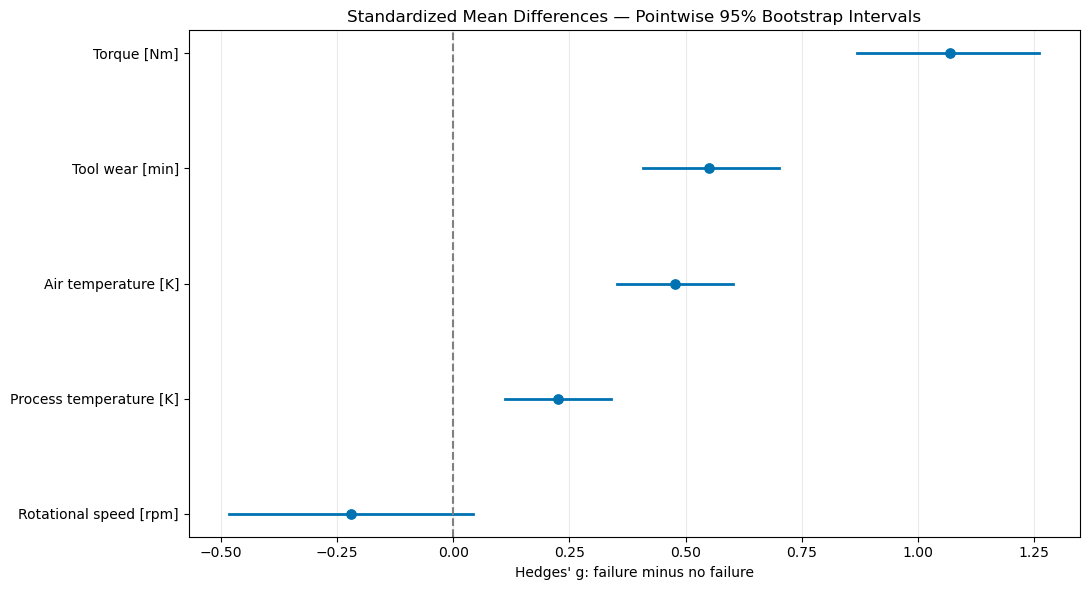

,mean_difference,mean_difference_CI_low,mean_difference_CI_high,hedges_g,hedges_g_bootstrap_CI_low,hedges_g_bootstrap_CI_high,Holm_adjusted_p_from_hypothesis_stage,reject_H0_after_Holm
sensor,,,,,,,,
Air temperature [K],0.94921,0.69974,1.19869,0.47705,0.35253,0.60112,0.00000,True
Process temperature [K],0.33404,0.16766,0.50041,0.22594,0.11208,0.33964,0.00019,True
Rotational speed [rpm],-39.98059,-86.74239,6.78121,-0.22105,-0.48246,0.04149,0.09348,False
Torque [Nm],10.52437,8.53105,12.51769,1.06971,0.86877,1.26182,0.00000,True
Tool wear [min],34.88415,25.82389,43.94442,0.55102,0.40872,0.70181,0.00000,True


In [5]:
ordered = sensor_statistics.sort_values("hedges_g")
fig, ax = plt.subplots(figsize=(11, 6))
for position, (sensor, row) in enumerate(ordered.iterrows()):
    ax.plot(
        [row["hedges_g_bootstrap_CI_low"], row["hedges_g_bootstrap_CI_high"]],
        [position, position], color="#0072B2", linewidth=2,
    )
    ax.scatter(row["hedges_g"], position, color="#0072B2", s=45, zorder=3)
ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks(np.arange(len(ordered)))
ax.set_yticklabels(ordered.index)
ax.set_xlabel("Hedges' g: failure minus no failure")
ax.set_title("Standardized Mean Differences — Pointwise 95% Bootstrap Intervals")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(VISUALS_DIR / "standardized_mean_differences.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

display(sensor_statistics[[
    "mean_difference", "mean_difference_CI_low", "mean_difference_CI_high",
    "hedges_g", "hedges_g_bootstrap_CI_low", "hedges_g_bootstrap_CI_high",
    "Holm_adjusted_p_from_hypothesis_stage", "reject_H0_after_Holm",
]].round(5))

supported = sensor_statistics.index[sensor_statistics["reject_H0_after_Holm"]].tolist()
unsupported = sensor_statistics.index[~sensor_statistics["reject_H0_after_Holm"]].tolist()
print("Evidence of mean differences after the existing Holm correction:", supported)
print("Insufficient evidence to reject equal means:", unsupported)
print("A nonsignificant mean comparison can coexist with differences in medians, tails, or nonlinear patterns.")


## 6. Describe failure rates by product type

I calculate the observed failure proportion for each product type and its individual 95% Wilson interval. These intervals show uncertainty under a binomial, independent-observation model. They are descriptive, not simultaneous pairwise tests or evidence that product type causes failures.


,observations,failures,failure_rate,failure_rate_CI_low,failure_rate_CI_high
Type,,,,,
L,4830,197,0.040787,0.035564,0.046740
M,2381,58,0.024360,0.018891,0.031360
H,789,16,0.020279,0.012520,0.032686


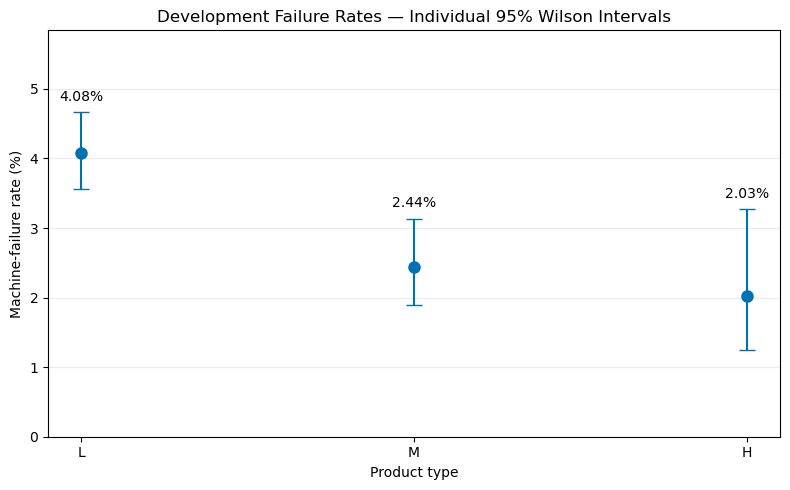

In [6]:
type_rows = []
for product_type in ["L", "M", "H"]:
    subset = analysis.loc[analysis["Type"].eq(product_type)]
    if subset.empty:
        raise ValueError(f"No development observations for product type {product_type}.")
    events = int(subset["Machine failure"].sum())
    n = len(subset)
    lower, upper = proportion_confint(events, n, alpha=ALPHA, method="wilson")
    type_rows.append({
        "Type": product_type,
        "observations": n,
        "failures": events,
        "failure_rate": events / n,
        "failure_rate_CI_low": float(lower),
        "failure_rate_CI_high": float(upper),
    })
type_rates = pd.DataFrame(type_rows).set_index("Type")
display(type_rates)

overall_lower, overall_upper = proportion_confint(
    int(analysis["Machine failure"].sum()), len(analysis),
    alpha=ALPHA, method="wilson",
)

fig, ax = plt.subplots(figsize=(8, 5))
rates = type_rates["failure_rate"].to_numpy() * 100
lower = type_rates["failure_rate_CI_low"].to_numpy() * 100
upper = type_rates["failure_rate_CI_high"].to_numpy() * 100
ax.errorbar(
    np.arange(len(type_rates)), rates,
    yerr=[rates - lower, upper - rates],
    fmt="o", color="#0072B2", capsize=6, markersize=8,
)
for position, rate in enumerate(rates):
    ax.annotate(
        f"{rate:.2f}%", (position, upper[position]),
        xytext=(0, 8), textcoords="offset points", ha="center",
    )
ax.set_xticks(np.arange(len(type_rates)))
ax.set_xticklabels(type_rates.index)
ax.set_xlabel("Product type")
ax.set_ylabel("Machine-failure rate (%)")
ax.set_ylim(0, max(upper) * 1.25)
ax.set_title("Development Failure Rates — Individual 95% Wilson Intervals")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(VISUALS_DIR / "product_type_failure_rates.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 7. Inspect failure flags and overlapping events

I distinguish the overall failure target from the five failure indicators. For each flag, I report counts both with and without an overall failure label.

The fraction of target failures with a given flag uses only target-failure observations in its numerator and denominator. Flags can overlap, so these percentages need not sum to 100%.

I retain target/flag disagreements and save them for review. These flags describe outcomes and will not be used as predictors of the overall failure label.


Target / any-flag disagreements retained: 21
Observations with multiple active failure flags: 22


,flagged_development_rows,flagged_with_target_failure,flagged_without_target_failure,percent_of_development_rows,percent_of_target_failures_with_flag
flag,,,,,
TWF,36,36,0,0.450,13.284
HDF,86,86,0,1.075,31.734
PWF,82,82,0,1.025,30.258
OSF,82,82,0,1.025,30.258
RNF,15,1,14,0.188,0.369


,TWF,HDF,PWF,OSF,RNF
TWF,36,0,1,2,1
HDF,0,86,2,6,0
PWF,1,2,82,12,0
OSF,2,6,12,82,0
RNF,1,0,0,0,15


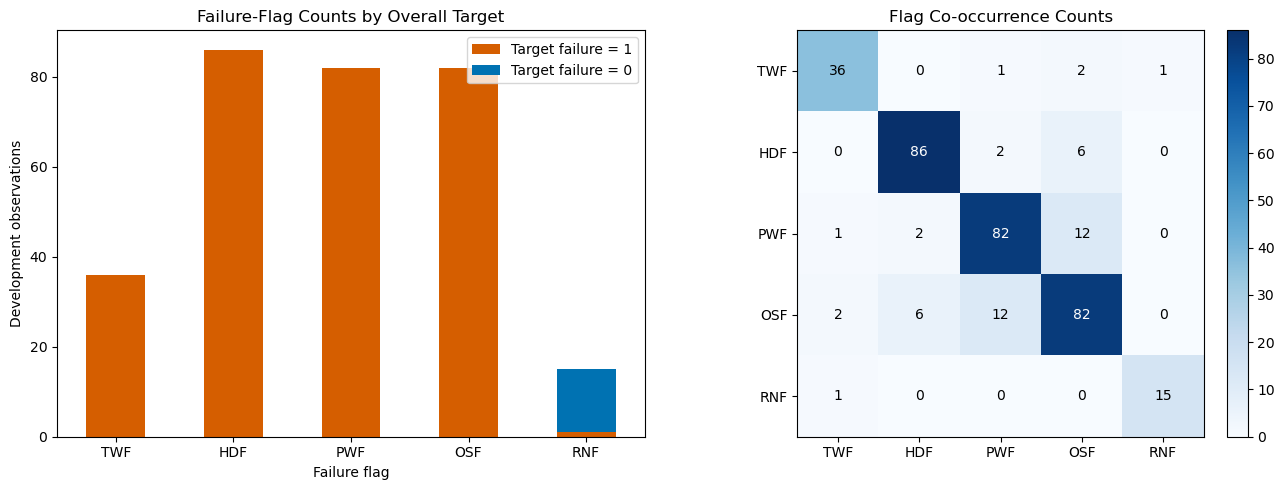

In [7]:
flag_rows = []
n_failures = len(failed)
for flag in FAILURE_FLAGS:
    active = analysis[flag].eq(1)
    with_failure = int((active & analysis["Machine failure"].eq(1)).sum())
    without_failure = int((active & analysis["Machine failure"].eq(0)).sum())
    flag_rows.append({
        "flag": flag,
        "flagged_development_rows": int(active.sum()),
        "flagged_with_target_failure": with_failure,
        "flagged_without_target_failure": without_failure,
        "percent_of_development_rows": float(active.mean()) * 100,
        "percent_of_target_failures_with_flag": with_failure / n_failures * 100,
    })
flag_summary = pd.DataFrame(flag_rows).set_index("flag")
flag_matrix = analysis[FAILURE_FLAGS].astype(int)
flag_overlap = flag_matrix.T.dot(flag_matrix)

any_flag = flag_matrix.eq(1).any(axis=1)
disagreement = any_flag.ne(analysis["Machine failure"].eq(1))
label_review = analysis.loc[
    disagreement, ["UDI", "Type", "Machine failure", *FAILURE_FLAGS]
].copy()
label_review["any_failure_flag"] = any_flag.loc[disagreement].astype(int)
label_review["review_reason"] = np.where(
    label_review["Machine failure"].eq(1),
    "target_1_without_failure_flag",
    "target_0_with_failure_flag",
)
multiple_flags = int(flag_matrix.sum(axis=1).gt(1).sum())

display(flag_summary.round(3))
display(flag_overlap)
print(f"Target / any-flag disagreements retained: {len(label_review)}")
print(f"Observations with multiple active failure flags: {multiple_flags}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
flag_summary[[
    "flagged_with_target_failure", "flagged_without_target_failure"
]].rename(columns={
    "flagged_with_target_failure": "Target failure = 1",
    "flagged_without_target_failure": "Target failure = 0",
}).plot.bar(
    stacked=True, ax=axes[0], color=[COLORS[1], COLORS[0]],
)
axes[0].set_title("Failure-Flag Counts by Overall Target")
axes[0].set_ylabel("Development observations")
axes[0].set_xlabel("Failure flag")
axes[0].tick_params(axis="x", rotation=0)
image = axes[1].imshow(flag_overlap.to_numpy(), cmap="Blues")
axes[1].set_xticks(np.arange(len(FAILURE_FLAGS)))
axes[1].set_yticks(np.arange(len(FAILURE_FLAGS)))
axes[1].set_xticklabels(FAILURE_FLAGS)
axes[1].set_yticklabels(FAILURE_FLAGS)
axes[1].set_title("Flag Co-occurrence Counts")
threshold = flag_overlap.to_numpy().max() / 2
for row in range(len(FAILURE_FLAGS)):
    for col in range(len(FAILURE_FLAGS)):
        value = int(flag_overlap.iloc[row, col])
        axes[1].text(
            col, row, str(value), ha="center", va="center",
            color="white" if value > threshold else "black",
        )
fig.colorbar(image, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(VISUALS_DIR / "failure_flags_and_overlap.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 8. Save results and summarize this run

I export the statistics, rate summaries, failure-flag tables, review records, and analysis settings. I preserve both the input data and the existing hypothesis-testing decisions.


In [8]:
sensor_statistics.to_csv(REPORTS_DIR / "sensor_statistics.csv")
type_rates.to_csv(REPORTS_DIR / "product_type_failure_rates.csv")
flag_summary.to_csv(REPORTS_DIR / "failure_flag_summary.csv")
flag_overlap.to_csv(REPORTS_DIR / "failure_flag_overlap.csv")
label_review.to_csv(REPORTS_DIR / "target_flag_disagreements.csv", index=False)
analysis[["UDI", "split", "Machine failure"]].to_csv(
    REPORTS_DIR / "analysis_observations.csv", index=False,
)

summary = {
    "analysis_rows": int(len(analysis)),
    "no_failure_rows": int(len(not_failed)),
    "failure_rows": int(len(failed)),
    "failure_rate": float(analysis["Machine failure"].mean()),
    "failure_rate_individual_Wilson_CI": [float(overall_lower), float(overall_upper)],
    "included_splits": ["train", "validation"],
    "excluded_final_test_rows": int(len(test_udi)),
    "final_test_used": False,
    "input_files": {
        name: {
            "relative_path": path.relative_to(PROJECT_ROOT).as_posix(),
            "sha256": input_checksums[name],
        }
        for name, path in input_paths.items()
    },
    "group_difference_direction": "failure minus no failure",
    "mean_comparison": "Welch two-sided t-test, equivalent to the prior two-group Welch ANOVA",
    "primary_decisions": "Reuse the six-test Holm-adjusted H2 decisions from 04_hypothesis_testing.ipynb",
    "alpha": ALPHA,
    "effect_scale": "Sample-size-weighted pooled SD; Cohen d and bias-corrected Hedges g",
    "bootstrap": {
        "method": "Separate within-outcome-group percentile bootstrap for Hedges g",
        "repeats": BOOTSTRAP_REPEATS,
        "base_seed": SEED,
        "seed_per_sensor": "base_seed + sensor list position",
        "interval": "Pointwise 95%; not simultaneous",
    },
    "sensors_with_Holm_evidence_of_mean_difference": supported,
    "sensors_without_Holm_evidence_of_mean_difference": unsupported,
    "target_flag_disagreements_retained": int(len(label_review)),
    "rows_with_multiple_failure_flags": multiple_flags,
    "class_balancing_applied": False,
    "interpretation": "Exploratory associations in synthetic development data; not causal or predictive importance.",
    "versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "statsmodels": statsmodels.__version__,
    },
}
(REPORTS_DIR / "analysis_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8",
)

for name, path in input_paths.items():
    if sha256(path) != input_checksums[name]:
        raise RuntimeError(f"Input file changed during the run: {name}")

print(f"Development failure rate: {summary['failure_rate']:.2%}")
print(
    "Individual 95% Wilson interval: "
    f"{overall_lower:.2%} to {overall_upper:.2%}"
)
print(f"Sensors with corrected evidence of mean differences: {len(supported)} / {len(SENSOR_COLUMNS)}")
print(f"Target / failure-flag disagreements retained: {len(label_review)}")
print(f"Saved reports to: {REPORTS_DIR.relative_to(PROJECT_ROOT)}")
print(f"Saved charts to: {VISUALS_DIR.relative_to(PROJECT_ROOT)}")
print("Verified: all input files remain unchanged.")


Development failure rate: 3.39%
Individual 95% Wilson interval: 3.01% to 3.81%
Sensors with corrected evidence of mean differences: 4 / 5
Target / failure-flag disagreements retained: 21
Saved reports to: reports\failure_statistics
Saved charts to: visuals\failure_statistics
Verified: all input files remain unchanged.


## Interpretation and next steps

I interpret the mean differences, effect sizes, intervals, and distribution plots together. A small p-value is not a measure of effect size. A large group difference also does not establish that a sensor is a strong independent predictor or a cause of failure.

These results reuse the sample already explored in the preceding notebooks. Bootstrap and analytic intervals depend on sampling assumptions, and the synthetic data do not establish reliability on real machines. Product-type rates and failure-flag overlaps are descriptive.

Next, I train baseline prediction models using sensor inputs and product type, with identifiers and failure-outcome flags excluded. I keep the saved final-test split reserved for model evaluation.
